# Model A: Custom CNN

This notebook develops a simple Custom CNN model
to classify real and AI-generated images.

The notebook uses Google Colab for model training
and GitHub for project and model storage.

In [19]:
import os
import subprocess
from pathlib import Path

REPO_URL = (
    "https://github.com/Michaelatj/"
    "AI-Generated-Image-Classification-using-CNN.git"
)

REPO_DIR = Path(
    "/content/AI-Generated-Image-Classification-using-CNN"
)

# Clone repository
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

# Set working directory
os.chdir(REPO_DIR)

print("Connected to repository!")
print("Working directory:", Path.cwd())

Connected to repository!
Working directory: /content/AI-Generated-Image-Classification-using-CNN


## Load Dataset

Load the prepared CSV manifest and retrieve
the original image from Hugging Face.

The target variable is label_a:
- 0 = Real
- 1 = AI-Generated

,image_id,source_split,row_idx,caption_group_id,caption,label_a,label_a_name,label_b,label_b_name
0,train_000000,train,0,6dfa76b111164685,Two tall giraffe standing next to each other o...,0,Real,0,Real
1,train_000001,train,1,6dfa76b111164685,Two tall giraffe standing next to each other o...,1,AI-Generated,1,Stable Diffusion 2.1
2,train_000002,train,2,6dfa76b111164685,Two tall giraffe standing next to each other o...,1,AI-Generated,2,Stable Diffusion XL (SDXL)
3,train_000003,train,3,6dfa76b111164685,Two tall giraffe standing next to each other o...,1,AI-Generated,3,Stable Diffusion 3
4,train_000004,train,4,6dfa76b111164685,Two tall giraffe standing next to each other o...,1,AI-Generated,4,DALL-E 3


Image size: (640, 480)
Label: 0


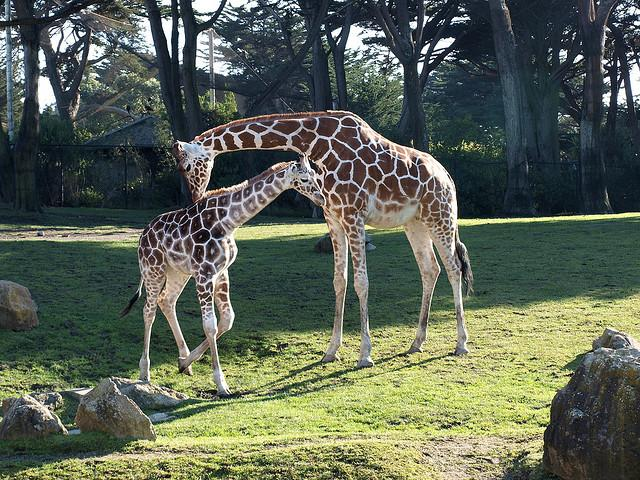

In [21]:
!pip install -q datasets

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from itertools import islice
from PIL import Image as PILImage
from IPython.display import display

# Load training manifest
train_df = pd.read_csv(
    "artifacts/splits/train.csv"
)

display(train_df.head())

# Select one sample
row = train_df.iloc[0]

# Load original Hugging Face split
DATASET_ID = "Rajarshi-Roy-research/Defactify_Image_Dataset"

hf_dataset = load_dataset(
    DATASET_ID,
    split=row["source_split"],
    streaming=True
)

# Retrieve image using row_idx
row_idx = int(row["row_idx"])

sample = next(
    islice(hf_dataset, row_idx, row_idx + 1),
    None
)

if sample is None:
    raise ValueError("Image not found!")

# Verify label mapping
assert int(sample["Label_A"]) == int(row["label_a"])

image = sample["Image"].convert("RGB")

print("Image size:", image.size)
print("Label:", row["label_a"])

display(image)

## Custom CNN Architecture

Build a simple CNN from scratch.

Architecture:
- Input: 224 × 224 × 3
- Conv2D: 32 filters
- MaxPooling
- Conv2D: 64 filters
- MaxPooling
- Global Average Pooling
- Dense: 64 neurons
- Output: Sigmoid

Task: Binary Image Classification.

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMAGE_SIZE = 224

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,617 (92.25 KB)

 Trainable params: 23,617 (92.25 KB)

 Non-trainable params: 0 (0.00 B)

## Test Training

Perform a small training test using one image
to verify that the CNN can train successfully.

This is only an integration test, not a meaningful
model performance experiment.

In [23]:
# Preprocess image
image_resized = image.resize(
    (IMAGE_SIZE, IMAGE_SIZE)
)

x = np.array(
    image_resized,
    dtype=np.float32
)

x = np.expand_dims(x, axis=0)

# Prepare label
y = np.array(
    [[int(row["label_a"])]],
    dtype=np.float32
)

# Test one training step
history = model.fit(
    x,
    y,
    epochs=1,
    verbose=1
)

# Create model directory
MODEL_DIR = Path("artifacts/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save test model
MODEL_PATH = MODEL_DIR / "custom_cnn_integration_test.keras"

model.save(MODEL_PATH)

print("\nModel saved successfully!")
print("Location:", MODEL_PATH.resolve())

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0000e+00 - loss: 0.7092

Model saved successfully!
Location: /content/AI-Generated-Image-Classification-using-CNN/artifacts/models/custom_cnn_integration_test.keras


## Save Model to GitHub

Commit and push the trained model artifact
to the project repository.

The model will be stored in:

artifacts/models/

In [25]:
from google.colab import userdata
import base64

# Get GitHub token securely
token = userdata.get("GITHUB_TOKEN")

if not token:
    raise ValueError("GITHUB_TOKEN is missing!")

# Configure Git identity
subprocess.run(
    ["git", "config", "user.name", "Michael Andreas Tjendra"],
    check=True
)

git_email = input("Your GitHub email: ")

subprocess.run(
    ["git", "config", "user.email", git_email],
    check=True
)

# Stage model
subprocess.run(
    ["git", "add", "artifacts/models/custom_cnn_integration_test.keras"],
    check=True
)

# Commit
subprocess.run(
    ["git", "commit", "-m", "Add Custom CNN integration test"],
    check=True
)

# Authenticate and push
credentials = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraHeader=AUTHORIZATION: basic {credentials}",
        "push",
        "origin",
        "main"
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("GitHub push failed.")

print("Successfully pushed to GitHub!")

Your GitHub email: alongbest2000@gmail.com


CalledProcessError: Command '['git', 'add', 'artifacts/models/custom_cnn_integration_test.keras']' returned non-zero exit status 1.

In [26]:
from pathlib import Path
import subprocess

REPO_DIR = Path(
    "/content/AI-Generated-Image-Classification-using-CNN"
)

MODEL_PATH = (
    REPO_DIR /
    "artifacts/models/custom_cnn_integration_test.keras"
)

print("Repository exists:", REPO_DIR.exists())
print("Model exists:", MODEL_PATH.exists())

print("\nModel directory contents:")

model_dir = REPO_DIR / "artifacts/models"

if model_dir.exists():
    for file in model_dir.iterdir():
        print(file.name, f"{file.stat().st_size / 1024:.2f} KB")

print("\nGit status:")

result = subprocess.run(
    ["git", "-C", str(REPO_DIR), "status", "--short"],
    capture_output=True,
    text=True
)

print(result.stdout)

print("\nGit ignore check:")

result = subprocess.run(
    [
        "git", "-C", str(REPO_DIR),
        "check-ignore", "-v",
        "artifacts/models/custom_cnn_integration_test.keras"
    ],
    capture_output=True,
    text=True
)

print(result.stdout or "File is not ignored.")

Repository exists: True
Model exists: True

Model directory contents:
custom_cnn_integration_test.keras 315.50 KB
.gitkeep 0.00 KB

Git status:


Git ignore check:
.gitignore:42:artifacts/models/*	artifacts/models/custom_cnn_integration_test.keras



In [28]:
subprocess.run(
    [
        "git", "-C", str(REPO_DIR),
        "add", "-f",
        "artifacts/models/custom_cnn_integration_test.keras"
    ],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/AI-Generated-Image-Classification-using-CNN', 'add', '-f', 'artifacts/models/custom_cnn_integration_test.keras'], returncode=0)

In [29]:
MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

model.save(MODEL_PATH)

print("Model saved:", MODEL_PATH.exists())

Model saved: True


In [30]:
import subprocess
import base64
from google.colab import userdata

# Check staged files
staged = subprocess.check_output(
    ["git", "diff", "--cached", "--name-only"],
    cwd=REPO_DIR,
    text=True
)

print("Staged files:")
print(staged)

# Commit model
subprocess.run(
    [
        "git", "commit",
        "-m", "Add Custom CNN integration test model"
    ],
    cwd=REPO_DIR,
    check=True
)

# Retrieve token
token = userdata.get("GITHUB_TOKEN")

credentials = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

# Push to GitHub
result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraHeader=AUTHORIZATION: basic {credentials}",
        "push",
        "origin",
        "main"
    ],
    cwd=REPO_DIR,
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("GitHub push failed!")

print(result.stdout)
print("Successfully pushed model to GitHub!")

Staged files:
artifacts/models/custom_cnn_integration_test.keras

remote: Permission to Michaelatj/AI-Generated-Image-Classification-using-CNN.git denied to Michaelatj.
fatal: unable to access 'https://github.com/Michaelatj/AI-Generated-Image-Classification-using-CNN.git/': The requested URL returned error: 403



RuntimeError: GitHub push failed!